# Model 3 — 08 Threshold Analysis

## Threshold diagnostic
Test whether the binary F1 problem is mainly a decision-threshold issue. Do not promote the selected threshold directly from this holdout.

Project root:
c:\Users\bimal\OneDrive\Desktop\EVIDENT

Data directory:
c:\Users\bimal\OneDrive\Desktop\EVIDENT\data\raw\behaviour

Production model directory:
c:\Users\bimal\OneDrive\Desktop\EVIDENT\models\behavior\production

Production model loaded successfully.
Model: c:\Users\bimal\OneDrive\Desktop\EVIDENT\models\behavior\production\network_threat_model.pkl
Number of expected features: 67

Dataset path:
c:\Users\bimal\OneDrive\Desktop\EVIDENT\data\raw\behaviour\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Dataset loaded successfully.
Dataset shape: (225745, 79)

Binary target distribution:
Label
1    128027
0     97718
Name: count, dtype: int64

Target percentages:
Label
1    56.71
0    43.29
Name: proportion, dtype: float64

Feature matrix:
Rows: 225745
Columns: 67

Generating model probabilities...
Probability generation complete.

Probability statistics:
count    225745.000000
mean          0.568912
std           0.494250
min           0.000002
25%           0.000022
50%   

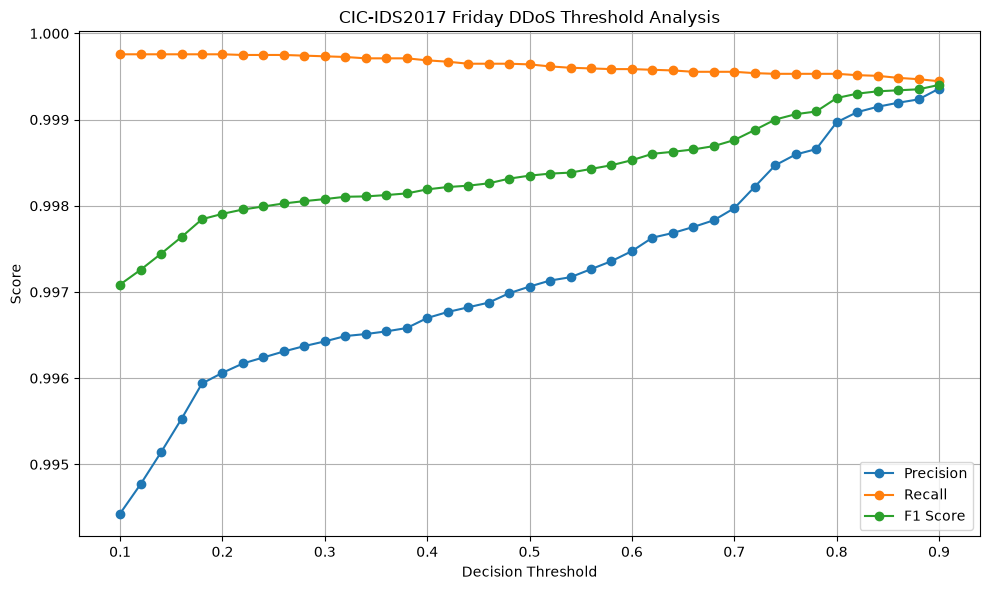


IMPORTANT
This threshold analysis is diagnostic only.
Do NOT change the production model threshold based solely on this holdout dataset.
The selected threshold must be validated using an independent validation/calibration procedure before production promotion.


In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. LOCATE EVIDENT PROJECT ROOT
# ============================================================

PROJECT_ROOT = Path.cwd()

while (
    PROJECT_ROOT.name != "EVIDENT"
    and PROJECT_ROOT.parent != PROJECT_ROOT
):
    PROJECT_ROOT = PROJECT_ROOT.parent

if PROJECT_ROOT.name != "EVIDENT":
    raise FileNotFoundError(
        "Could not locate the EVIDENT project root."
    )

print("Project root:")
print(PROJECT_ROOT)


# ============================================================
# 2. DEFINE PROJECT DIRECTORIES
# ============================================================

# Dataset directory
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "behaviour"

# Model directories
MODEL_DIR = PROJECT_ROOT / "models" / "behavior"
META_DIR = MODEL_DIR / "metadata"
PROD_DIR = MODEL_DIR / "production"

META_DIR.mkdir(parents=True, exist_ok=True)

print("\nData directory:")
print(DATA_DIR)

print("\nProduction model directory:")
print(PROD_DIR)


# ============================================================
# 3. LOAD PRODUCTION MODEL
# ============================================================

MODEL_PATH = PROD_DIR / "network_threat_model.pkl"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"\nProduction model not found:\n{MODEL_PATH}"
    )

artifact = joblib.load(MODEL_PATH)

model = artifact["binary_model"]
features = artifact["feature_columns"]

print("\nProduction model loaded successfully.")
print("Model:", MODEL_PATH)
print("Number of expected features:", len(features))


# ============================================================
# 4. LOCATE FRIDAY DDOS DATASET
# ============================================================

TARGET_FILE = "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

# IMPORTANT:
# DATA_DIR already points to:
# EVIDENT/data/raw/behaviour
#
# Therefore DO NOT append raw/behaviour again.

path = DATA_DIR / TARGET_FILE


# ------------------------------------------------------------
# If not found, search the whole EVIDENT project
# ------------------------------------------------------------

if not path.exists():

    print("\nDataset not found at expected location.")
    print("Searching the EVIDENT project...")

    matches = list(PROJECT_ROOT.rglob(TARGET_FILE))

    if len(matches) > 0:
        path = matches[0]
        print("Dataset found at:")
        print(path)

    else:
        raise FileNotFoundError(
            "\nCould not find the required CIC-IDS2017 dataset:\n"
            f"{TARGET_FILE}\n\n"
            "Expected location:\n"
            f"{DATA_DIR / TARGET_FILE}\n\n"
            "Please place the CSV in:\n"
            f"{DATA_DIR}"
        )


print("\nDataset path:")
print(path)


# ============================================================
# 5. LOAD DATASET
# ============================================================

df = pd.read_csv(
    path,
    low_memory=False
)

# Clean column names
df.columns = [
    str(c).strip().replace("\ufeff", "")
    for c in df.columns
]

print("\nDataset loaded successfully.")
print("Dataset shape:", df.shape)


# ============================================================
# 6. VALIDATE LABEL COLUMN
# ============================================================

if "Label" not in df.columns:
    raise ValueError(
        "'Label' column was not found in the dataset.\n\n"
        f"Available columns:\n{list(df.columns)}"
    )


# ============================================================
# 7. CREATE BINARY TARGET
# ============================================================

y = (
    df["Label"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace(" ", "_", regex=False)
    != "BENIGN"
).astype(int)


print("\nBinary target distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ============================================================
# 8. PREPARE FEATURES
# ============================================================

X = df.reindex(
    columns=features
).copy()


# ------------------------------------------------------------
# Convert features to numeric
# ------------------------------------------------------------

for column in features:
    X[column] = pd.to_numeric(
        X[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# Replace infinite values
# ------------------------------------------------------------

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


print("\nFeature matrix:")
print("Rows:", X.shape[0])
print("Columns:", X.shape[1])


# ============================================================
# 9. MODEL PREDICTIONS
# ============================================================

print("\nGenerating model probabilities...")

probabilities = model.predict_proba(X)[:, 1]

print("Probability generation complete.")

print("\nProbability statistics:")
print(
    pd.Series(probabilities).describe()
)


# ============================================================
# 10. THRESHOLD ANALYSIS
# ============================================================

print("\nRunning threshold analysis...")

results = []

# Thresholds from 0.10 to 0.90
thresholds = np.arange(
    0.10,
    0.91,
    0.02
)

for threshold in thresholds:

    # Convert probabilities into binary predictions
    predictions = (
        probabilities >= threshold
    ).astype(int)


    # Precision / Recall / F1
    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y,
            predictions,
            average="binary",
            zero_division=0
        )
    )


    # Confusion matrix
    cm = confusion_matrix(
        y,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # False positive rate
    false_positive_rate = (
        fp / max(tn + fp, 1)
    )


    results.append(
        {
            "threshold": round(
                float(threshold),
                2
            ),

            "precision": float(
                precision
            ),

            "recall": float(
                recall
            ),

            "f1": float(
                f1
            ),

            "false_positive_rate": float(
                false_positive_rate
            ),

            "true_negatives": int(tn),

            "false_positives": int(fp),

            "false_negatives": int(fn),

            "true_positives": int(tp)
        }
    )


# ============================================================
# 11. CREATE RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(results)

# Sort by F1 score
results_sorted = results_df.sort_values(
    "f1",
    ascending=False
)


# ============================================================
# 12. DISPLAY BEST THRESHOLDS
# ============================================================

print("\n" + "=" * 80)
print("TOP THRESHOLDS BY F1 SCORE")
print("=" * 80)

print(
    results_sorted.head(10).to_string(
        index=False
    )
)


# ============================================================
# 13. BEST THRESHOLD
# ============================================================

best_row = results_sorted.iloc[0]

best_threshold = best_row["threshold"]
best_f1 = best_row["f1"]
best_precision = best_row["precision"]
best_recall = best_row["recall"]
best_fpr = best_row["false_positive_rate"]


print("\n" + "=" * 80)
print("BEST THRESHOLD")
print("=" * 80)

print(
    f"Threshold          : {best_threshold:.2f}"
)

print(
    f"Precision          : {best_precision:.4f}"
)

print(
    f"Recall             : {best_recall:.4f}"
)

print(
    f"F1 Score           : {best_f1:.4f}"
)

print(
    f"False Positive Rate: {best_fpr:.4f}"
)


# ============================================================
# 14. SAVE RESULTS
# ============================================================

output_path = (
    META_DIR /
    "threshold_analysis_friday_ddos.csv"
)

results_df.to_csv(
    output_path,
    index=False
)

print("\nThreshold analysis saved to:")
print(output_path)


# ============================================================
# 15. OPTIONAL VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["threshold"],
    results_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["threshold"],
    results_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["threshold"],
    results_df["f1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "CIC-IDS2017 Friday DDoS Threshold Analysis"
)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 16. IMPORTANT QUALITY-GATE MESSAGE
# ============================================================

print("\n" + "=" * 80)
print("IMPORTANT")
print("=" * 80)

print(
    "This threshold analysis is diagnostic only."
)

print(
    "Do NOT change the production model threshold based solely "
    "on this holdout dataset."
)

print(
    "The selected threshold must be validated using an "
    "independent validation/calibration procedure before "
    "production promotion."
)